In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

url = "https://raw.githubusercontent.com/jeffrey125/Mall-Customer-Segmentation/master/Mall_Customers.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]

X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

K-MEANS

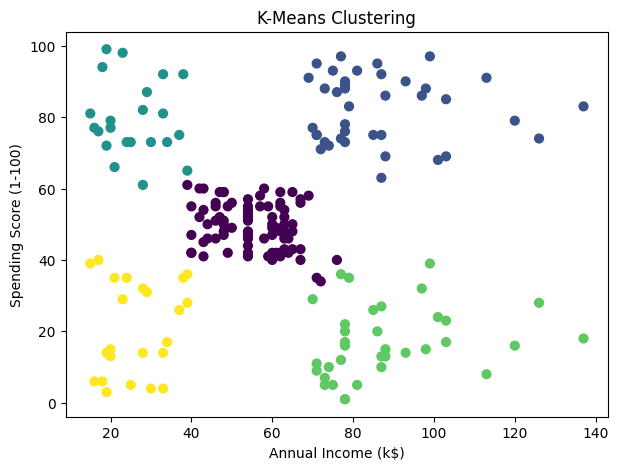

In [ ]:
kmeans = KMeans(
    n_clusters=5,
    init="k-means++",
    n_init=10,
    random_state=42
)

kmeans_labels = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1],
            c=kmeans_labels, cmap="viridis", s=40)

plt.xlabel(features[0])
plt.ylabel(features[1])
plt.title("K-Means Clustering")
plt.show()

AGGLOMETRIVE

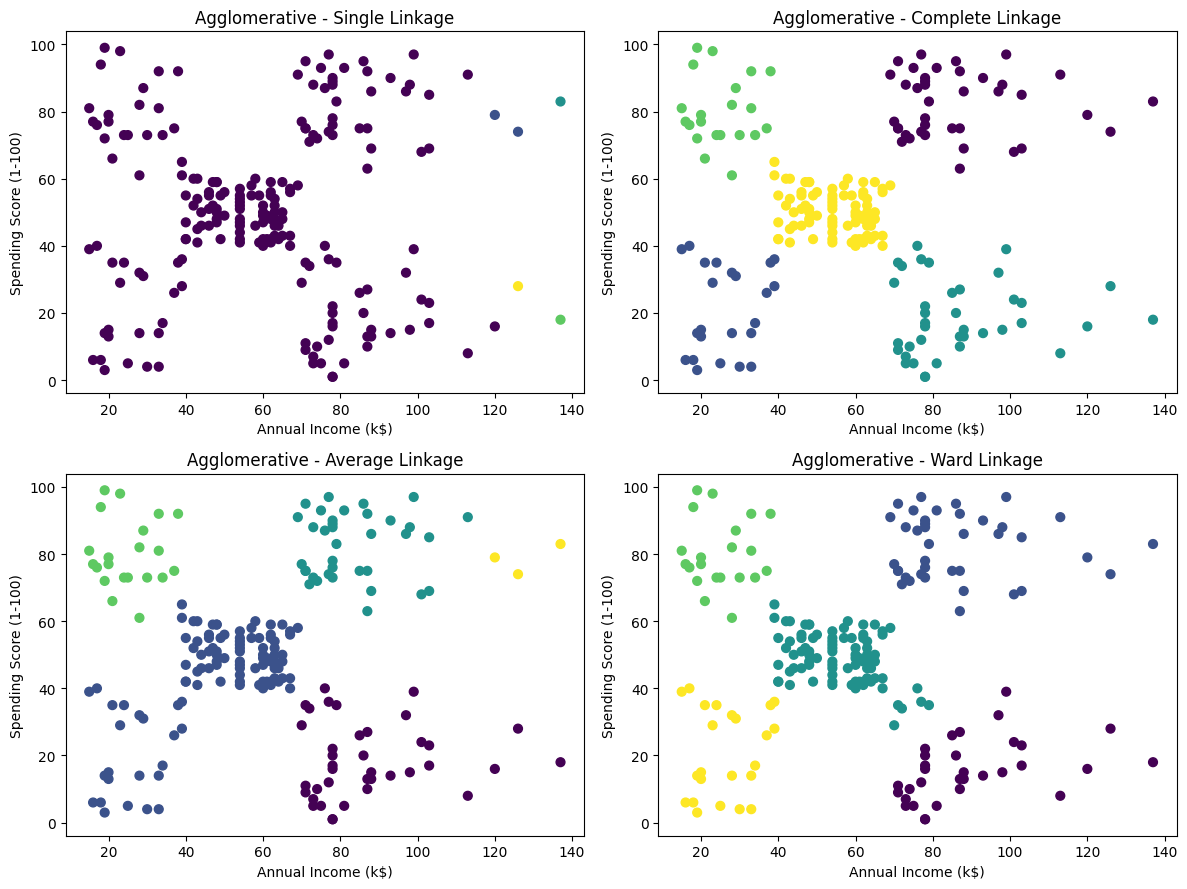

In [ ]:
linkages = ["single", "complete", "average", "ward"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for i, linkage in enumerate(linkages):
    model = AgglomerativeClustering(
        n_clusters=5,
        linkage=linkage
    )

    labels = model.fit_predict(X_scaled)

    axes[i].scatter(
        X.iloc[:, 0],
        X.iloc[:, 1],
        c=labels,
        cmap="viridis",
        s=40
    )

    axes[i].set_title(f"Agglomerative - {linkage.title()} Linkage")
    axes[i].set_xlabel(features[0])
    axes[i].set_ylabel(features[1])

plt.tight_layout()
plt.show()

DBSCAN

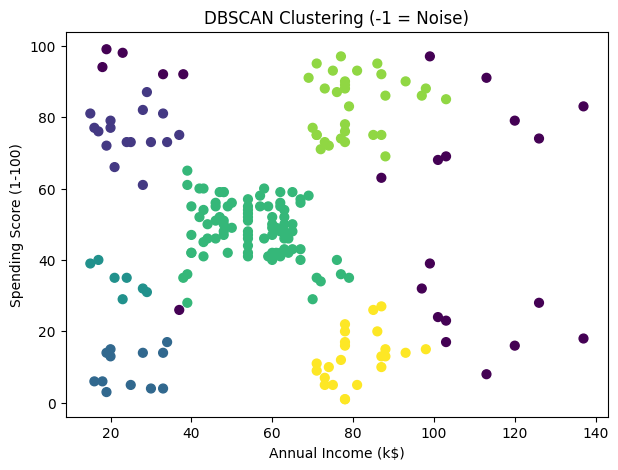

DBSCAN labels: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Noise points: 23


In [ ]:
dbscan = DBSCAN(
    eps=0.35,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=dbscan_labels,
    cmap="viridis",
    s=40
)

plt.xlabel(features[0])
plt.ylabel(features[1])
plt.title("DBSCAN Clustering (-1 = Noise)")
plt.show()

print("DBSCAN labels:", sorted(set(dbscan_labels)))
print("Noise points:", sum(dbscan_labels == -1))

In [ ]:
results = {
    "K-Means": kmeans_labels,
    "Agglomerative Single": AgglomerativeClustering(
        n_clusters=5, linkage="single"
    ).fit_predict(X_scaled),
    "Agglomerative Complete": AgglomerativeClustering(
        n_clusters=5, linkage="complete"
    ).fit_predict(X_scaled),
    "Agglomerative Average": AgglomerativeClustering(
        n_clusters=5, linkage="average"
    ).fit_predict(X_scaled),
    "Agglomerative Ward": AgglomerativeClustering(
        n_clusters=5, linkage="ward"
    ).fit_predict(X_scaled),
    "DBSCAN": dbscan_labels
}

for name, labels in results.items():
    print(f"\n{name}")
    print(pd.Series(labels).value_counts().sort_index())


K-Means
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Agglomerative Single
0    195
1      2
2      1
3      1
4      1
Name: count, dtype: int64

Agglomerative Complete
0    39
1    23
2    38
3    21
4    79
Name: count, dtype: int64

Agglomerative Average
0     38
1    102
2     36
3     21
4      3
Name: count, dtype: int64

Agglomerative Ward
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64

DBSCAN
-1    23
 0    16
 1    12
 2     7
 3    88
 4    31
 5    23
Name: count, dtype: int64
